## Network / Swarm: 
Agents handoff directly to each other. If Agent_A realizes it can't finish the job, it directly returns a routing instruction to send state straight to Agent_B without an intermediary supervisor overseeing every step.

# Network / Swarm Pattern (Peer-to-Peer):

Structure: Agents operate as a decentralized mesh. Any agent can dynamically hand off control directly to another agent based on the context of the conversation.

Pros: Highly flexible, great for open-ended creative tasks or complex back-and-forth collaborations.

Cons: Harder to trace, prone to infinite loops or coordination failures if routing logic isn't tightly bounded.

In [1]:
from langgraph.graph import END, StateGraph
from typing_extensions import Annotated, TypedDict
from langgraph.checkpoint.memory import MemorySaver

import operator

In [2]:
# 1. Shared State with active agent tracking
class State(TypedDict):
  messages: Annotated[list, operator.add]
  active_agent: str

In [3]:
# 2. Agent A (Triage / Research Agent)
def research_agent(state: State):
  print("\n--- [Research Agent Active] ---")
  last_msg = state["messages"][-1].lower()

  # If research discovers it needs code execution, it directly hands off to Code Agent
  if "code" in last_msg or "script" in last_msg:
    print("--> [Handoff]: Research Agent transferring control directly to Code Agent")
    return {
        "messages": ["Handing off to Code Agent."],
        "active_agent": "code_agent",
    }
  # Otherwise it finishes the work itself
  return {
      "messages": ["Research completed."],
      "active_agent": "FINISH",
  }

In [4]:
# 3. Agent B (Code Execution Agent)
def code_agent(state: State):
  print("\n--- [Code Agent Active] ---")
  last_msg = state["messages"][-1].lower()

  # If code agent needs doc verification, it can hand back directly to Research Agent
  if "verify" in last_msg or "docs" in last_msg:
    print("Code Agent transferring control directly back to Research Agent")
    return {
        "messages": ["Code Agent: Code generated, but needs doc verification.Code Agent transferring control directly to Research Agent"],
        "active_agent": "research_agent",
    }
  # Finish task
  return {
      "messages": ["Code Agent: Executed script successfully."],
      "active_agent": "FINISH",
  }

In [5]:
# 4. Peer Routing Function
def route_peer_handoff(state: State):
  next_agent = state.get("active_agent", "FINISH")
  return next_agent

In [6]:
# 5. Build Graph
workflow = StateGraph(State)

workflow.add_node("research_agent", research_agent)
workflow.add_node("code_agent", code_agent)

# Set starting point (e.g., initial entry point)
workflow.set_entry_point("research_agent")

# Direct Peer-to-Peer routing edges
workflow.add_conditional_edges(
    "research_agent",
    route_peer_handoff,
    {
        "code_agent": "code_agent",
        "FINISH": END,
    },
)

workflow.add_conditional_edges(
    "code_agent",
    route_peer_handoff,
    {
        "research_agent": "research_agent",
        "FINISH": END,
    },
)

checkpointer = MemorySaver()
app = workflow.compile(checkpointer=checkpointer)

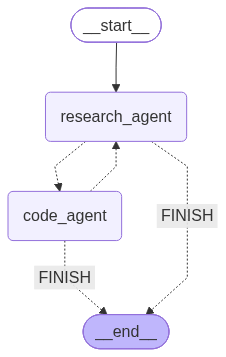

In [7]:
app

In [8]:
config = {
    "configurable": {
        "thread_id": "swarm_test_1"
    },
    "recursion_limit": 10
}


print("Running Swarm Handoff Test:")
result = app.invoke(
    {"messages": ["Research how to write a script and write the code for it."]},
    config=config,
)

print("\nFinal Message History:")
for msg in result["messages"]:
  print(f" - {msg}")

Running Swarm Handoff Test:

--- [Research Agent Active] ---
--> [Handoff]: Research Agent transferring control directly to Code Agent

--- [Code Agent Active] ---

Final Message History:
 - Research how to write a script and write the code for it.
 - Handing off to Code Agent.
 - Code Agent: Executed script successfully.
